<a href="https://colab.research.google.com/github/alexandraselektor/music-project/blob/main/%D7%91%D7%99%D7%A0%D7%94_%D7%9E%D7%9C%D7%90%D7%9B%D7%95%D7%AA%D7%99%D7%AA_%D7%A4%D7%A8%D7%95%D7%99%D7%A7%D7%98_%D7%A4%D7%95%D7%A4%D7%95%D7%9C%D7%A8%D7%99%D7%95%D7%AA_%D7%9E%D7%A2%D7%95%D7%93%D7%9B%D7%9F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# שאלת המחקר:

איזה מודל (מהמודלים הנבחרים) ינבא את רמת הפופולריות של שיר על פי מאפייניו המוזיקליים בצורה הטובה ביותר?

 import data

In [ ]:

import pandas as pd

# Install gdown if you haven't already
!pip install gdown

# Google Drive file ID
file_id = '1KAK7I_Wt8V2AN_MP6Td4J96oPmEhvVcC'

# Output filename
output_filename = 'your_file_name.csv'

# Download the file
!gdown --id {file_id} -O {output_filename}

# Load the CSV file into a pandas DataFrame
df = pd.read_csv(output_filename)

# Display the first 5 rows of the DataFrame
display(df.head())

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1KAK7I_Wt8V2AN_MP6Td4J96oPmEhvVcC
To: /content/your_file_name.csv
100% 20.2M/20.2M [00:00<00:00, 82.9MB/s]


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


The dataset was sourced from Kaggle and was uploaded by user MaharshiPandya in 2023. It achieved a perfect usability score of 10.00 out of 10.00, reflecting its completeness, reliability, and compatibility.

This dataset contains comprehensive data on tracks from the digital music platform Spotify, enabling an examination of the relationship between musical characteristics and song popularity. Each observation represents a single track, and the dataset includes quantitative data regarding the song's audio features, alongside descriptive information about the track and artist identity.

The raw dataset comprises 114,000 observations and 21 variables. The dependent variable is the song's popularity, measured as a numerical value ranging from 0 to 100. Popularity is calculated via an algorithm based on the total number of plays and the recency of those plays. Generally speaking, songs that are currently being played frequently will have a higher popularity score than songs that were frequently played in the past. The remaining variables describe various musical characteristics, production features, and general track information.

# data wrangling


Identifying duplicate tracks based on song title and artist name.

In [ ]:

# 2. הגדרת הקריטריון לכפילות: שם השיר ושם האמן
cols_to_check = ['track_name', 'artists']

# 3. מחיקה מוחלטת של כל שיר שמופיע יותר מפעם אחת
# keep=False אומר: אם השיר מופיע פעמיים או יותר, תמחק את כל המופעים שלו
df_fully_cleaned = df.drop_duplicates(subset=cols_to_check, keep=False)

# 4. הדפסת סיכום הפעולה
rows_removed = len(df) - len(df_fully_cleaned)
print(f"שורות במקור: {len(df)}")
print(f"שורות שנמחקו (כל השירים שהיו להם כפילויות): {rows_removed}")
print(f"שורות שנותרו (שירים שהופיעו רק פעם אחת בלבד): {len(df_fully_cleaned)}")

# 5. שמירת הקובץ החדש
output_name = 'spotify_no_duplicates_at_all.csv'
df_fully_cleaned.to_csv(output_name, index=False)
print(f"הקובץ נשמר בהצלחה בשם: {output_name}")
display(df_fully_cleaned)

שורות במקור: 114000
שורות שנמחקו (כל השירים שהיו להם כפילויות): 49157
שורות שנותרו (שירים שהופיעו רק פעם אחת בלבד): 64843
הקובץ נשמר בהצלחה בשם: spotify_no_duplicates_at_all.csv


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,...,-9.734,1,0.0557,0.210,0.000000,0.1170,0.1200,76.332,4,acoustic
14,14,4LbWtBkN82ZRhz9jqzgrb3,Chord Overstreet;Deepend,Hold On (Remix),Hold On - Remix,56,188133,False,0.755,0.780,...,-6.084,1,0.0327,0.124,0.000028,0.1210,0.3870,120.004,4,acoustic
19,19,6CgNoAbFJ4Q4Id4EjtbXlC,Boyce Avenue;Bea Miller,"Cover Sessions, Vol. 4",Photograph,67,260186,False,0.717,0.320,...,-8.393,1,0.0283,0.830,0.000000,0.1070,0.3220,107.946,4,acoustic
21,21,210JCw2LbYD4YIs8GiZ9iP,Boyce Avenue;Jennel Garcia,"Cover Sessions, Vol. 3",Demons,63,174174,False,0.678,0.351,...,-8.654,1,0.0266,0.747,0.000000,0.3550,0.5690,90.032,4,acoustic
32,32,1m5LC29RE52Bxy7hxvpOlL,Chord Overstreet,Christmas Country Songs 2022,All I Want For Christmas Is A Real Good Tan,0,234186,False,0.593,0.455,...,-8.192,1,0.0388,0.366,0.000000,0.0914,0.5640,202.019,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.235,...,-16.393,1,0.0422,0.640,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.117,...,-18.318,0,0.0401,0.994,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.329,...,-10.895,0,0.0420,0.867,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.506,...,-10.889,1,0.0297,0.381,0.000000,0.2700,0.4130,135.960,4,world-music


filtering of NA.

In [ ]:
df_fully_cleaned.isna().sum()+df_fully_cleaned.eq("").sum()
#קיימים רק 3 תאים רקים בכל הנתונים, ביחס לכמות הנתונים זה מעט מאוד לכן נסיר אותם
df_clean = df_fully_cleaned.dropna()
df_clean.isna().sum()+df_clean.eq("").sum()
#כעת קובץ הנתונים נקי לגמרי,נשמור אותו
output_name = 'spotify_clean.csv'
df_clean.to_csv(output_name, index=False)
print(f"הקובץ נשמר בהצלחה בשם: {output_name}")


הקובץ נשמר בהצלחה בשם: spotify_clean.csv


As stated by the dataset author, values of 0.66 and above in the 'speechiness' musical feature indicate non-musical content (such as podcasts). Therefore, we filtered these out to focus solely on songs.

In [ ]:
# מספר שורות לפני הסינון
rows_before = df_clean.shape[0]

# סינון שירים עם speechiness <= 0.66
df_clean = df_clean[df_clean["speechiness"] <= 0.66]

# מספר שורות אחרי הסינון
rows_after = df_clean.shape[0]

# סיכום
print(f"Rows before speechiness filter: {rows_before}")
print(f"Rows after speechiness filter:  {rows_after}")
print(f"Rows removed:               {rows_before - rows_after}")
print(f"Percentage removed:         {((rows_before - rows_after) / rows_before) * 100:.2f}%")


Rows before speechiness filter: 64842
Rows after speechiness filter:  63995
Rows removed:               847
Percentage removed:         1.31%


# EDA-סטטיסטיקה תיאורית


In [ ]:
from numpy import transpose
transpose(df_clean.describe().round(2))

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,63995.0,56913.50,33631.75,2.00,27121.50,54820.00,84563.00,113999.00
popularity,63995.0,33.72,17.79,0.00,21.00,33.00,47.00,99.00
duration_ms,63995.0,232630.23,121479.14,8586.00,173067.50,215803.00,269516.00,5237295.00
danceability,63995.0,0.56,0.18,0.00,0.44,0.57,0.69,0.98
energy,63995.0,0.63,0.26,0.00,0.45,0.67,0.86,1.00
key,63995.0,5.28,3.56,0.00,2.00,5.00,8.00,11.00
loudness,63995.0,-8.74,5.46,-49.53,-10.60,-7.35,-5.20,4.53
mode,63995.0,0.63,0.48,0.00,0.00,1.00,1.00,1.00
speechiness,63995.0,0.08,0.08,0.00,0.04,0.05,0.09,0.66
acousticness,63995.0,0.33,0.34,0.00,0.02,0.20,0.63,1.00


As can be seen in the table, the min of tempo is 0.00, which is impossible for a song. In addition, the range of duration_ms is very wide (from 0.1431 minutes to 87.28825 minutes). Those indicate that the data set still contains "not songs". For the next step we will want to filter those out.

זיהוי ערכים קיצוניים נוספים וטיפול בהם (outliers)

filtering of tempo 0.00.

In [ ]:

# שלב 1: הסרת ערכים לא תקינים (tempo == 0)
rows_before = df_clean.shape[0]
df_clean = df_clean[df_clean["tempo"] != 0]
rows_after = df_clean.shape[0]

print(f"Rows removed where tempo == 0: {rows_before - rows_after}")

# שלב 2: חישוב חריגים מחדש עבור tempo (IQR)
Q1 = df_clean["tempo"].quantile(0.25)
Q3 = df_clean["tempo"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# זיהוי חריגים
outliers_tempo = df_clean[
    (df_clean["tempo"] < lower_bound) |
    (df_clean["tempo"] > upper_bound)
]

print("\nUpdated IQR bounds for tempo:")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")

print(f"Number of tempo outliers after removing tempo=0: {outliers_tempo.shape[0]}")
print(f"Percentage of tempo outliers: {outliers_tempo.shape[0] / df_clean.shape[0] * 100:.2f}%")




Rows removed where tempo == 0: 135

Updated IQR bounds for tempo:
Lower bound: 38.84
Upper bound: 201.37
Number of tempo outliers after removing tempo=0: 233
Percentage of tempo outliers: 0.36%


filtering of duration.

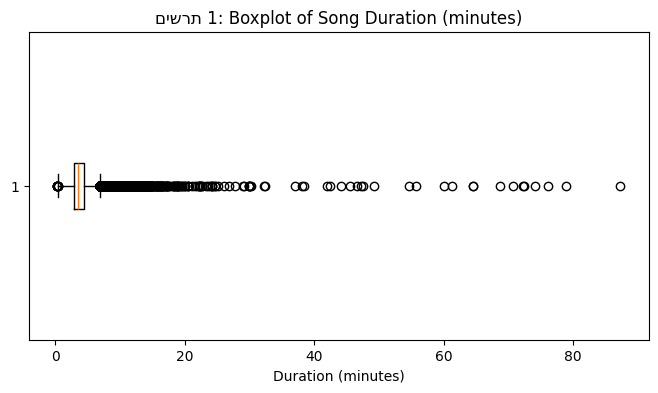

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
# Convert duration from milliseconds to minutes for plotting
plt.boxplot(df_clean["duration_ms"] / 60000, vert=False)
plt.xlabel("Duration (minutes)")
plt.title("םישרת 1: Boxplot of Song Duration (minutes)")
plt.show()

In [ ]:

###אחוז השירים מכל ג'אנר שארוכים מ-4.5 דקות וקצרים מ-12 דקות
###כלומר, כמה אחוז ממהשירים בכל גאנר נמצאים ברבעון העליון

# 1) רבעון עליון של משך הזמן
q3_duration = df_clean["duration_ms"].quantile(0.75)

# 2) סה"כ שירים בכל ז'אנר
genre_total = df_clean.groupby("track_genre").size()

# 3) שירים שנמצאים ברבעון העליון של משך הזמן בכל ז'אנר
genre_top_duration = df_clean[df_clean["duration_ms"] >= q3_duration].groupby("track_genre").size()

# 4) טבלה מסכמת
genre_duration_summary = pd.DataFrame({
    "total_songs": genre_total,
    "top_duration_songs": genre_top_duration
}).fillna(0)

# 5) אחוז השירים הארוכים (רבעון עליון) מתוך כל ז'אנר
genre_duration_summary["top_duration_percent"] = (
    genre_duration_summary["top_duration_songs"] / genre_duration_summary["total_songs"] * 100
)

# 6) מיון ועיגול
genre_duration_summary = (
    genre_duration_summary
    .sort_values("top_duration_percent", ascending=False)
    .round(2)
)

print(f"Q3 duration_ms = {q3_duration:.0f} ms (~{q3_duration/60000:.2f} minutes)")
genre_duration_summary

genre_duration_50_plus = genre_duration_summary[
    genre_duration_summary["top_duration_percent"] >= 50
]

genre_duration_50_plus



Q3 duration_ms = 269594 ms (~4.49 minutes)


,total_songs,top_duration_songs,top_duration_percent
track_genre,,,
minimal-techno,600,490,81.67
detroit-techno,884,689,77.94
chicago-house,871,658,75.55
pop-film,624,395,63.30
techno,363,222,61.16
gospel,623,381,61.16
iranian,911,543,59.60
black-metal,867,510,58.82
world-music,840,447,53.21


In [ ]:

# -----------------------------
# 1) Filter by duration: keep only songs between 1 and 12 minutes
#    (duration is in milliseconds)
# -----------------------------
MIN_MS = 60_000        # 1 minute
MAX_MS = 720_000       # 12 minutes

rows_before = df_clean.shape[0]

# Keep rows within the range
df_clean = df_clean[(df_clean["duration_ms"] >= MIN_MS) & (df_clean["duration_ms"] <= MAX_MS)]

rows_after = df_clean.shape[0]
rows_removed = rows_before - rows_after

print(f"Rows before duration filter: {rows_before}")
print(f"Rows after duration filter:  {rows_after}")
print(f"Rows removed:               {rows_removed} ({rows_removed/rows_before*100:.2f}%)")

# -----------------------------
# 2) Recompute IQR outliers for duration_ms after filtering
# -----------------------------
Q1 = df_clean["duration_ms"].quantile(0.25)
Q3 = df_clean["duration_ms"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_duration = df_clean[(df_clean["duration_ms"] < lower_bound) | (df_clean["duration_ms"] > upper_bound)]

print("\nUpdated IQR bounds for duration_ms (after filtering):")
print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")

print(f"\nNumber of duration_ms outliers after filtering: {outliers_duration.shape[0]}")
print(f"Percentage of duration_ms outliers: {outliers_duration.shape[0] / df_clean.shape[0] * 100:.2f}%")

#נשמור את הדאטה אחרי מחיקת טמפו=0 ושירים ארוכים מ-12 דקות וקצרים מדקה
df_clean.to_csv("spotify_clean_without_outliers.csv", index=False)
df_clean = pd.read_csv("spotify_clean_without_outliers.csv")

df_clean.shape

Rows before duration filter: 63860
Rows after duration filter:  62997
Rows removed:               863 (1.35%)

Updated IQR bounds for duration_ms (after filtering):
Q1: 174504.00
Q3: 269533.00
IQR: 95029.00
Lower bound: 31960.50
Upper bound: 412076.50

Number of duration_ms outliers after filtering: 2728
Percentage of duration_ms outliers: 4.33%


(62997, 21)

Now we will want to choose which variables to use. Firstly, we will test the correlation of musical features.

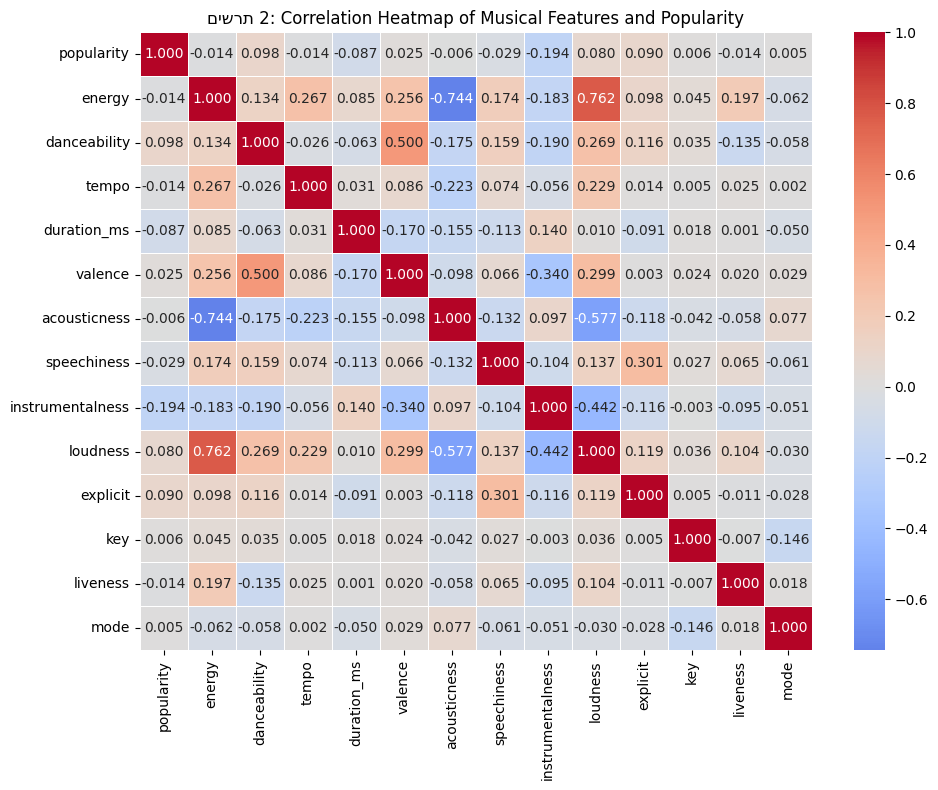

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
#בחינת קורולציה בין משתנים
# בחירת המשתנים הרלוונטיים
# רשימת המשתנים לניתוח
corr_features = [
    "popularity",
    "energy",
    "danceability",
    "tempo",
    "duration_ms",
    "valence",
    "acousticness",
    "speechiness",
    "instrumentalness",
    "loudness",
    "explicit",
    "key",
    "liveness",
    "mode"
]

# חישוב מטריצת הקורלציה
corr_matrix = df_clean[corr_features].corr()

# ציור Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,          # הצגת ערכי הקורלציה
    fmt=".3f",           # עיגול ל-3 ספרות
    cmap="coolwarm",     # צבעים ברורים (שלילי-חיובי)
    center=0,            # מרכז צבעים ב-0
    linewidths=0.5
)

plt.title("םישרת 2: Correlation Heatmap of Musical Features and Popularity")
plt.tight_layout()
plt.show()

Two high correlations (exceeding 0.7) were observed between 'energy' and the variables 'loudness' and 'acousticness'. Consequently, 'energy' will be excluded from the model. The reason being because we want to minimize the musical features in order to reduce model complexity and prevent overfitting, thereby creating a more robust predictor.

In [ ]:
import pandas as pd
import numpy as np


# בחירת עמודות רלוונטיות לשאלת המחקר
candidate_cols = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "key",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",

]

# שמירה רק על עמודות שקיימות בפועל
relevant_cols = [c for c in candidate_cols if c in df_clean.columns]

# הסרת עמודות אינדקס טכניות אם קיימות
relevant_cols = [
    c for c in relevant_cols
    if c.lower() not in ["unnamed: 0", "index", "id"]
]

# 3️⃣ שמירה רק על משתנים מספריים
numeric_relevant_cols = [
    c for c in relevant_cols
    if pd.api.types.is_numeric_dtype(df_clean[c])
]

print("Columns used for IQR outlier detection:")
print(numeric_relevant_cols)

# 4️⃣ חישוב ערכים קיצוניים לפי IQR
outliers_summary = []
outliers_mask_by_col = {}

for col in numeric_relevant_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)
    outliers_mask_by_col[col] = mask

    outliers_count = int(mask.sum())
    outliers_percent = (outliers_count / len(df_clean)) * 100

    outliers_summary.append({
        "variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outliers_count": outliers_count,
        "outliers_percent": round(outliers_percent, 2),
    })

outliers_df = (
    pd.DataFrame(outliers_summary)
    .sort_values(by="outliers_count", ascending=False)
    .reset_index(drop=True)
)

display(outliers_df)

# ✅ 5) (Optional) Get rows that are outliers in ANY relevant numeric column
any_outlier_mask = np.column_stack([outliers_mask_by_col[c].values for c in numeric_relevant_cols]).any(axis=1)
df_outliers_any = df_clean.loc[any_outlier_mask].copy()

print(f"\nRows that are outliers in at least one relevant column: {df_outliers_any.shape[0]} / {df_clean.shape[0]}")
display(df_outliers_any.head(10))

# ✅ 6) (Optional) If you want a cleaned df with outlier rows removed (ANY-column rule):
df_no_outliers_any = df_clean.loc[~any_outlier_mask].copy()
print(f"\nDataset after removing ANY-column outlier rows: {df_no_outliers_any.shape[0]} / {df_clean.shape[0]}")


Columns used for IQR outlier detection:
['popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


,variable,Q1,Q3,IQR,lower_bound,upper_bound,outliers_count,outliers_percent
0,instrumentalness,0.0000,0.2580,0.2580,-0.38700,0.64500,12135,19.26
1,speechiness,0.0362,0.0863,0.0501,-0.03895,0.16145,7296,11.58
2,liveness,0.0982,0.2770,0.1788,-0.17000,0.54520,4811,7.64
3,loudness,-10.5280,-5.1890,5.3390,-18.53650,2.81950,3597,5.71
4,duration_ms,174504.0000,269533.0000,95029.0000,31960.50000,412076.50000,2728,4.33
5,tempo,99.8860,140.6310,40.7450,38.76850,201.74850,211,0.33
6,danceability,0.4440,0.6920,0.2480,0.07200,1.06400,142,0.23
7,popularity,21.0000,47.0000,26.0000,-18.00000,86.00000,38,0.06
8,energy,0.4500,0.8580,0.4080,-0.16200,1.47000,0,0.00
9,key,2.0000,8.0000,6.0000,-7.00000,17.00000,0,0.00



Rows that are outliers in at least one relevant column: 24179 / 62997


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
4,32,1m5LC29RE52Bxy7hxvpOlL,Chord Overstreet,Christmas Country Songs 2022,All I Want For Christmas Is A Real Good Tan,0,234186,False,0.593,0.4550,...,-8.192,1,0.0388,0.366,0.000000,0.0914,0.5640,202.019,4,acoustic
12,62,7x4b0UccXSKBWxWmjcrG2T,Kurt Cobain,Montage Of Heck: The Home Recordings,And I Love Her,66,124933,False,0.616,0.2820,...,-15.317,1,0.0331,0.983,0.833000,0.1300,0.4350,96.638,4,acoustic
33,117,65VhbQdqvozUntjnlFkFbZ,Kina Grannis,You Are My Sunshine,You Are My Sunshine,60,123609,False,0.664,0.0755,...,-19.836,1,0.0389,0.910,0.000000,0.1640,0.5750,80.004,1,acoustic
78,183,2f4jlGvGi3ZDGogXys5FUp,Rachael Yamagata,Something In the Rain (Music from the Original...,"La La La (Something In the Rain, Pt. 2) [Music...",44,219613,False,0.420,0.2000,...,-18.827,1,0.0492,0.929,0.490000,0.0758,0.1640,87.248,4,acoustic
153,283,38ssTLOvoZyL4CLa4ImDG9,Kina Grannis;Imaginary Future,What a Wonderful World,What a Wonderful World,51,137066,False,0.486,0.0399,...,-21.560,1,0.0405,0.953,0.000009,0.1150,0.1550,95.066,3,acoustic
183,324,7HSk4yGZxfjOkHyOvZrBQZ,John Frusciante,To Record Only Water For Ten Days (U.S. Version),Ramparts,53,70133,False,0.386,0.4280,...,-9.949,0,0.0295,0.951,0.882000,0.1620,0.7300,172.311,4,acoustic
189,333,0avtLG17MT8kDf9xc67Niv,Rodrigo y Gabriela,Rodrigo Y Gabriela,Tamacun,50,205800,False,0.588,0.9140,...,-7.442,1,0.0341,0.832,0.856000,0.1030,0.9710,128.553,4,acoustic
198,343,37jsciEAFxwyjXx0kV6aO6,Rail Yard Ghosts,Songs from the Lowdown,A Month from Now,34,192392,False,0.415,0.6190,...,-7.624,0,0.1230,0.946,0.000028,0.7990,0.7390,77.009,4,acoustic
203,353,1yycinn2WICj4UKGQ9xPjD,Ichiko Aoba,マホロボシヤ,太陽さん,55,144653,False,0.440,0.0353,...,-20.858,1,0.0522,0.990,0.003120,0.1080,0.3620,181.988,4,acoustic
204,354,5Z8O4RFAmjA13jrOYIgyXA,Kina Grannis,Oh What A Love,Oh What A Love,46,235135,False,0.457,0.0640,...,-19.928,1,0.0339,0.941,0.108000,0.1070,0.0647,147.824,3,acoustic



Dataset after removing ANY-column outlier rows: 38818 / 62997


In [ ]:
##טבלה תיאורית מסכמת למשתנים הרלוונטיים

features_for_analysis = [
    "popularity",
    "duration_ms",
    "danceability",
    "key",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]
descriptive_stats = df_clean[features_for_analysis].describe().T
descriptive_stats_rounded = descriptive_stats.round(2)
descriptive_stats_rounded



,count,mean,std,min,25%,50%,75%,max
popularity,62997.0,33.87,17.80,0.00,21.00,33.00,47.00,99.00
duration_ms,62997.0,230878.04,88039.59,60000.00,174504.00,216386.00,269533.00,719306.00
danceability,62997.0,0.56,0.18,0.05,0.44,0.57,0.69,0.98
key,62997.0,5.29,3.56,0.00,2.00,5.00,8.00,11.00
loudness,62997.0,-8.67,5.36,-46.59,-10.53,-7.32,-5.19,4.53
speechiness,62997.0,0.08,0.08,0.02,0.04,0.05,0.09,0.66
acousticness,62997.0,0.33,0.34,0.00,0.02,0.19,0.63,1.00
instrumentalness,62997.0,0.20,0.34,0.00,0.00,0.00,0.26,1.00
liveness,62997.0,0.22,0.19,0.01,0.10,0.13,0.28,1.00
valence,62997.0,0.46,0.27,0.00,0.24,0.45,0.68,1.00


Quick glance at the distribution prior to models.

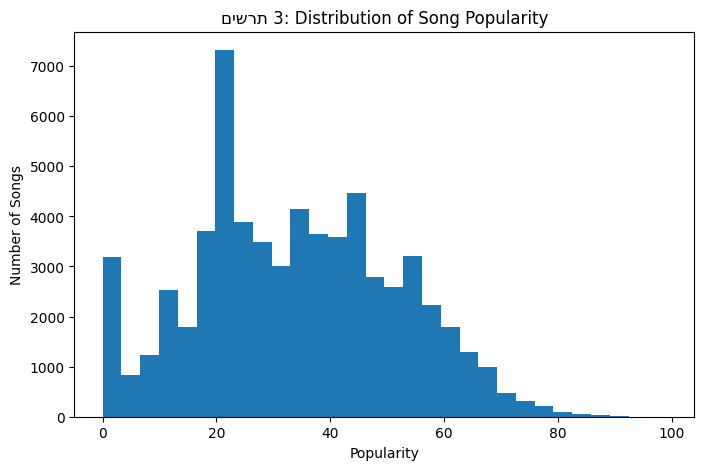

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df_clean["popularity"], bins=30)
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")
plt.title("םישרת 3: Distribution of Song Popularity")
plt.show()


**Small Model**:


*   duration_ms
*   danceability
*   loudness
*   valence
*   tempo
*   acousticness





The small model includes fundamental continuous features like tempo, energy, valence, loudness, and song length. We chose these variables because they directly impact the listening experience, are available for all songs, and provide a solid, interpretable basis for predicting popularity. This allows us to build a straightforward baseline model to compare against larger models that use more complex features.*italicized text*

**Large Model:**
*   duration_ms
*   danceability


*   valence
*   tempo


*   acousticness
*   speechiness



*   instrumentalness
*   liveness


*   explicit
*   loudness



*   key















As can be seen by the skewed distribution, there are less songs with popularity 60 and more, thus we understand that the models will be struggling more to predict songs in that range, we will adress this later with the results of the models.

KNN

Cross-Validation

We are using a 5-Fold Cross-Validation. As described before, it evaluates two  models—a "Small" feature set and a "Large" feature set—across a range of K=1 to 20. We are using StandardScaler that standardizes the features ("Nirmool). The performance is measured using the Mean Absolute Error (MAE), and the optimal K for each model is selected based on the lowest average cross-validation error.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# -----------------------------
# שלב 1: הגדרות כלליות
# -----------------------------
TARGET_COL = "popularity"
RANDOM_STATE = 42
CV_FOLDS = 5
N_REPEATS = 3
K_RANGE = range(1, 21)   # K בין 1 ל-20

# -----------------------------
# שלב 2: סטים של משתנים
# -----------------------------
features_small = [
    "duration_ms",
    "danceability",
    "loudness",
    "valence",
    "tempo",
    "acousticness"
]

features_large = [
    "duration_ms",
    "danceability",
    "valence",
    "tempo",
    "acousticness",
    "speechiness",
    "instrumentalness",
    "liveness",
    "explicit",
    "loudness",
    "key"
]

# -----------------------------
# שלב 3: פונקציה להרצת CV על טווח K
# -----------------------------
def run_knn_cv(df_in, feature_cols, model_name):
    # שימוש בדאטה הנקי
    data = df_in[feature_cols + [TARGET_COL]].dropna().copy()
    X = data[feature_cols]
    y = data[TARGET_COL]

    # Cross-Validation : RepeatedKFold
    cv = RepeatedKFold(
        n_splits=CV_FOLDS,
        n_repeats=N_REPEATS,
        random_state=RANDOM_STATE
    )

    # -----------------------------
    # 1: טיפול נכון ב-key ו-explicit
    # -----------------------------
    cat_cols = [c for c in ["key"] if c in feature_cols]
    bin_cols = [c for c in ["explicit"] if c in feature_cols]
    num_cols = [c for c in feature_cols if c not in (cat_cols + bin_cols)]

    # תאימות בין גרסאות sklearn (sparse_output vs sparse)
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", ohe, cat_cols),
            ("bin", "passthrough", bin_cols),
        ],
        remainder="drop"
    )

    rows = []

    for k in K_RANGE:
        pipe = Pipeline([
            ("preprocess", preprocessor),
            ("knn", KNeighborsRegressor(n_neighbors=k))
        ])

        # MAE מוחזר כשלילי
        cv_scores = cross_val_score(
            pipe,
            X,
            y,
            scoring="neg_mean_absolute_error",
            cv=cv,
            n_jobs=-1
        )

        mean_mae = -cv_scores.mean()

        rows.append({
            "model": model_name,
            "k": k,
            "cv_MAE": mean_mae
        })

    k_table = pd.DataFrame(rows).sort_values("cv_MAE").reset_index(drop=True)
    best_k = int(k_table.loc[0, "k"])
    best_mae = float(k_table.loc[0, "cv_MAE"])

    summary = {
        "model": model_name,
        "n_rows_used": int(len(data)),
        "n_features_input": int(len(feature_cols)),
        "cv": f"RepeatedKFold({CV_FOLDS} folds x {N_REPEATS} repeats)",
        "k_range": "1–20",
        "best_k": best_k,
        "cv_MAE(best_k)": round(best_mae, 3)
    }

    return summary, k_table

# -----------------------------
# שלב 4: הרצה – מודל מצומצם
# -----------------------------
results_small, k_table_small = run_knn_cv(
    df_in=df_clean,
    feature_cols=features_small,
    model_name="KNN - Small (CV)"
)

# -----------------------------
# שלב 5: הרצה – מודל מורחב
# -----------------------------
results_large, k_table_large = run_knn_cv(
    df_in=df_clean,
    feature_cols=features_large,
    model_name="KNN - Large (CV)"
)

# -----------------------------
# שלב 6: טבלת סיכום סופית
# -----------------------------
results_df = pd.DataFrame([results_small, results_large])
results_df


,model,n_rows_used,n_features_input,cv,k_range,best_k,cv_MAE(best_k)
0,KNN - Small (CV),62997,6,RepeatedKFold(5 folds x 3 repeats),1–20,20,13.517
1,KNN - Large (CV),62997,11,RepeatedKFold(5 folds x 3 repeats),1–20,20,13.395


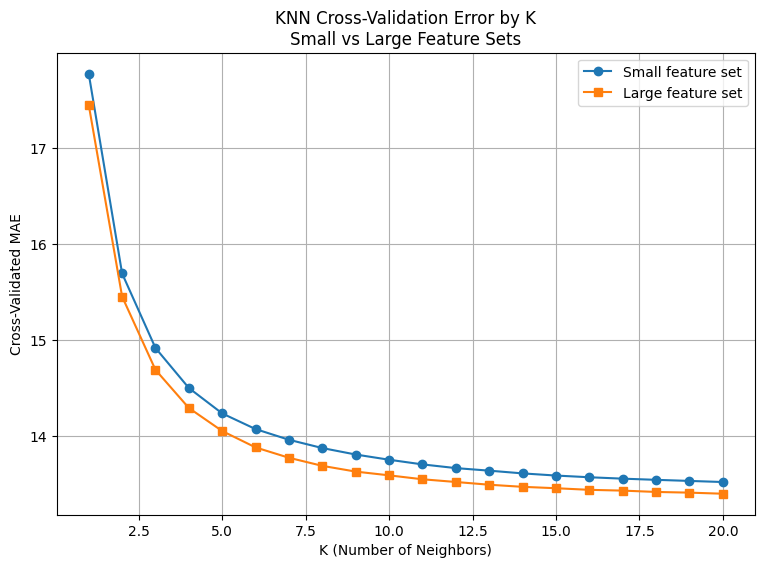

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# SMALL model
plt.plot(
    k_table_small["k"],
    k_table_small["cv_MAE"],
    marker="o",
    label="Small feature set"
)

# LARGE model
plt.plot(
    k_table_large["k"],
    k_table_large["cv_MAE"],
    marker="s",
    label="Large feature set"
)

plt.xlabel("K (Number of Neighbors)")
plt.ylabel("Cross-Validated MAE")
plt.title("KNN Cross-Validation Error by K\nSmall vs Large Feature Sets")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error

# -----------------------------
# הגדרות
# -----------------------------
BEST_K = 20
TEST_SIZE = 0.20

# -----------------------------
# Preprocess: טיפול נכון בנתונים ל-KNN
# -----------------------------
def build_preprocessor(feature_cols):
    cat_cols = [c for c in ["key"] if c in feature_cols]
    bin_cols = [c for c in ["explicit"] if c in feature_cols]
    num_cols = [c for c in feature_cols if c not in (cat_cols + bin_cols)]

    # תאימות בין גרסאות sklearn (sparse_output vs sparse)
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", ohe, cat_cols),
            ("bin", "passthrough", bin_cols),
        ],
        remainder="drop"
    )

# -----------------------------
# Quartile Analysis (NO R2 + TOTAL)
# -----------------------------
def quartile_analysis_no_r2_with_total(y_train_for_threshold, y_test, y_pred):
    q75 = float(np.quantile(np.asarray(y_train_for_threshold), 0.75))

    y_test_arr = np.asarray(y_test)
    y_pred_arr = np.asarray(y_pred)

    mask_q1_q3 = y_test_arr <= q75
    mask_q4 = y_test_arr > q75

    def make_row(name, yt, yp, show_threshold):
        mae = mean_absolute_error(yt, yp)
        rmse = np.sqrt(mean_squared_error(yt, yp))
        mdae = median_absolute_error(yt, yp)
        bias = float(np.mean(np.asarray(yp) - np.asarray(yt)))

        return {
            "Group": name,
            "Threshold (Q75)": round(q75, 1) if show_threshold else "—",
            "Observations": int(len(yt)),
            "MAE": round(float(mae), 3),
            "RMSE": round(float(rmse), 3),
            "MdAE": round(float(mdae), 2),
            "Bias": round(bias, 3),
        }

    rows = [
        make_row("TOTAL", y_test_arr, y_pred_arr, show_threshold=False),
        make_row("Q1–Q3", y_test_arr[mask_q1_q3], y_pred_arr[mask_q1_q3], show_threshold=True),
        make_row("Q4", y_test_arr[mask_q4], y_pred_arr[mask_q4], show_threshold=True),
    ]

    return pd.DataFrame(rows)[
        ["Group", "Threshold (Q75)", "Observations", "MAE", "RMSE", "MdAE", "Bias"]
    ]

# -----------------------------
# ריצה מלאה למודל אחד: Train/Test + KNN(K=20) + Quartiles table
# -----------------------------
def run_knn_k20_quartiles(df_in, feature_cols, model_name):
    data = df_in[feature_cols + [TARGET_COL]].dropna().copy()
    X = data[feature_cols]
    y = data[TARGET_COL]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
    )

    pipe = Pipeline([
        ("preprocess", build_preprocessor(feature_cols)),
        ("knn", KNeighborsRegressor(n_neighbors=BEST_K))
    ])

    pipe.fit(X_train, y_train)
    y_pred_test = pipe.predict(X_test)

    quartiles_df = quartile_analysis_no_r2_with_total(
        y_train_for_threshold=y_train,  # Q75 מתוך TRAIN בלבד
        y_test=y_test,
        y_pred=y_pred_test
    )

    return quartiles_df, pipe

# ============================================================
# הרצה לשני הסטים + תצוגה
# ============================================================

quartiles_small, knn_small_final = run_knn_k20_quartiles(
    df_in=df_clean,
    feature_cols=features_small,
    model_name="SMALL"
)

quartiles_large, knn_large_final = run_knn_k20_quartiles(
    df_in=df_clean,
    feature_cols=features_large,
    model_name="LARGE"
)

print("Quartile Analysis (NO R2 + TOTAL) - SMALL model:")
display(quartiles_small)

print("\nQuartile Analysis (NO R2 + TOTAL) - LARGE model:")
display(quartiles_large)

Quartile Analysis (NO R2 + TOTAL) - SMALL model:


,Group,Threshold (Q75),Observations,MAE,RMSE,MdAE,Bias
0,TOTAL,—,12600,13.396,16.739,11.30,0.063
1,Q1–Q3,47.0,9528,10.991,14.193,8.85,6.805
2,Q4,47.0,3072,20.857,22.902,20.25,-20.848



Quartile Analysis (NO R2 + TOTAL) - LARGE model:


,Group,Threshold (Q75),Observations,MAE,RMSE,MdAE,Bias
0,TOTAL,—,12600,13.257,16.532,11.35,0.297
1,Q1–Q3,47.0,9528,10.972,14.156,8.90,6.948
2,Q4,47.0,3072,20.345,22.348,19.77,-20.332


עץ החלטה

Two Decision Tree Regressors—one using a small set of basic features and another using a larger, extended set—to predict song popularity. It splits the data into training and testing sets, trains the models, and then performs a segmented evaluation by dividing the test results into "regular" songs (the bottom 75%) and "hits" (the top 25%) again.

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import randint
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error

# --- שלב 1: הכנת הנתונים ורשימות המשתנים ---

df_clean_encoded = pd.get_dummies(df_clean, columns=['key'], prefix='key')

features_small = [
    "duration_ms",
    "danceability",
    "loudness",
    "valence",
    "tempo",
    "acousticness"
]

keys_list = [col for col in df_clean_encoded.columns if col.startswith('key_')]

features_large = [
    "duration_ms",
    "danceability",
    "valence",
    "tempo",
    "acousticness",
    "speechiness",
    "instrumentalness",
    "liveness",
    "explicit",
    "loudness"
] + keys_list # Add the list of one-hot encoded key columns



# --- שלב 2: פונקציית הניתוח המשלבת אופטימיזציה וטבלאות ---

def train_optimize_evaluate_tree(features_list, model_name):
    # הגדרת X ו-y
    X = df_clean_encoded[features_list]
    y = df_clean_encoded['popularity']

    # חלוקה ל-Train ו-Test
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # --- אופטימיזציה: מציאת הפרמטרים הכי טובים (במקום לקבוע ידנית) ---
    param_dist = {
        'max_depth': randint(5, 21),           # עומק בין 5 ל-20
        'min_samples_leaf': randint(10, 101),  # עלה בין 10 ל-100
        'min_samples_split': randint(20, 201)  # פיצול בין 20 ל-200
    }

    dt = DecisionTreeRegressor(random_state=42)

    # הרצת החיפוש האקראי
    random_search = RandomizedSearchCV(
        estimator=dt,
        param_distributions=param_dist,
        n_iter=50,  # מספר השילובים לבדיקה
        scoring='neg_mean_absolute_error',
        cv=5,
        n_jobs=-1,
        random_state=42
    )

    random_search.fit(X_train, y_train)

    # שמירת המודל המיטבי
    best_model = random_search.best_estimator_
    best_params = random_search.best_params_

    # יצירת מחרוזת טקסט שתופיע בטבלה
    params_str = f"Depth={best_params['max_depth']}, Leaf={best_params['min_samples_leaf']}"

    # חיזוי
    y_pred = best_model.predict(X_test)

    # --- ניתוח התוצאות לפי סגמנטים ---

    # חישוב הסף של הרבעון העליון (Q3)
    threshold_q75 = y_test.quantile(0.75)


    mask_q1_q3 = y_test <= threshold_q75  # שירים רגילים
    mask_q4 = y_test > threshold_q75      # להיטים

    all_segment_results = []

    # רשימת הקבוצות ללולאה
    groups = [
        ("Total", np.nan, np.ones(len(y_test), dtype=bool)),
        ("Q1-Q3", threshold_q75, mask_q1_q3),
        ("Q4", threshold_q75, mask_q4)
    ]

    for group_name, thresh, mask in groups:
        y_true_seg = y_test[mask]
        y_pred_seg = y_pred[mask]

        all_segment_results.append({
            'Group': group_name,
            'Threshold (Q75)': thresh,
            'Observations': len(y_true_seg),
            'MAE': round(mean_absolute_error(y_true_seg, y_pred_seg), 2),
            'RMSE': round(np.sqrt(mean_squared_error(y_true_seg, y_pred_seg)), 2),
            'MdAE': round(median_absolute_error(y_true_seg, y_pred_seg), 2),
            'Bias': round(np.mean(y_pred_seg - y_true_seg), 2),
            'Best Params': params_str if group_name == "Total" else "" # מציג רק בשורה הראשונה
        })

    return pd.DataFrame(all_segment_results)

# --- שלב 3: הרצה והצגת התוצאות ---

print("Evaluating Optimized Small Model...")
df_results_small = train_optimize_evaluate_tree(features_small, "Small Model")
display(df_results_small)

print("\n" + "="*80 + "\n")

print("Evaluating Optimized Large Model...")
dt_results_large = train_optimize_evaluate_tree(features_large, "Large Model") # Renamed variable
display(dt_results_large)

# --- סיכום ---
print("\n--- Summary of Optimized Decision Tree Performance ---")
print("1. Separate Optimization: Each model (Small/Large) found its own 'best fit' parameters (shown in the 'Best Params' column).")
print("2. Segmentation: We can clearly see the difference in errors between Regular songs (Q1-Q3) and Hits (Q4).")
print("3. Bias Analysis: Look at the 'Bias' column - a negative bias in Q4 indicates the model consistently underestimates hits.")

Evaluating Optimized Small Model...


,Group,Threshold (Q75),Observations,MAE,RMSE,MdAE,Bias,Best Params
0,Total,NaN,12600,13.46,16.81,11.50,-0.13,"Depth=15, Leaf=68"
1,Q1-Q3,47.0,9528,10.97,14.18,8.73,6.65,
2,Q4,47.0,3072,21.18,23.13,20.35,-21.18,




Evaluating Optimized Large Model...


,Group,Threshold (Q75),Observations,MAE,RMSE,MdAE,Bias,Best Params
0,Total,NaN,12600,13.15,16.50,11.15,-0.31,"Depth=13, Leaf=80"
1,Q1-Q3,47.0,9528,10.67,13.84,8.55,6.30,
2,Q4,47.0,3072,20.84,22.86,20.19,-20.82,



--- Summary of Optimized Decision Tree Performance ---
1. Separate Optimization: Each model (Small/Large) found its own 'best fit' parameters (shown in the 'Best Params' column).
2. Segmentation: We can clearly see the difference in errors between Regular songs (Q1-Q3) and Hits (Q4).
3. Bias Analysis: Look at the 'Bias' column - a negative bias in Q4 indicates the model consistently underestimates hits.


יער אקראי

Two Random Forest Regressor models, differentiating between a "Small" model
and a "Large" model that adds explicit content and one-hot encoded musical keys. After processing the data, it splits the data into training and testing sets, trains the models, and then performs a segmented evaluation by dividing the test results into "regular" songs (the bottom 75%) and "hits" (the top 25%) again.




In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error

# --- שלב 1: הכנת הנתונים וקידוד (Encoding) ---
# יצירת המשתנה df_clean_encoded מתוך df_clean המקורי
# זה פותר את השגיאה NameError: name 'df_clean_encoded' is not defined
df_clean_encoded = pd.get_dummies(df_clean, columns=['key'], prefix='key')

# סט מצומצם – 6 משתנים בסיסיים שלב 2
features_small = [
    "duration_ms",
    "danceability",
    "loudness",
    "valence",
    "tempo",
    "acousticness"
]

# כל עמודות ה-key המקודדות
keys_list = [c for c in df_clean_encoded.columns if c.startswith("key_")]

# סט מורחב – 11 משתנים (6 בסיסיים + 5 נוספים)
features_large = features_small + [
    "speechiness",
    "instrumentalness",
    "liveness",
    "explicit"
] + keys_list


# הסף שמופיע בתמונות שלך
threshold_val = 47.0

# --- שלב 3: פונקציית הניתוח המפיקה את מבנה הטבלה המבוקש ---
def get_detailed_analysis(features, model_label):
    X = df_clean_encoded[features]
    y = df_clean_encoded['popularity']

    # חלוקה לסט אימון ומבחן (80/20)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # אימון מודל יער אקראי
    model = RandomForestRegressor(n_estimators=1000, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # הגדרת הקבוצות לטבלה
    masks = [
        ("Total", np.nan, np.ones(len(y_test), dtype=bool)),   # כל המדגם
        ("Q1-Q3", threshold_val, y_test <= threshold_val),     # שירים רגילים
        ("Q4", threshold_val, y_test > threshold_val)          # להיטים
    ]

    results_rows = []
    for group_name, thresh, mask in masks:
        y_true_seg = y_test[mask]
        y_pred_seg = y_pred[mask]

        results_rows.append({
            "Group": group_name,
            "Threshold (Q75)": thresh,
            "Observations": len(y_true_seg),
            "MAE": round(mean_absolute_error(y_true_seg, y_pred_seg), 2),
            "RMSE": round(np.sqrt(mean_squared_error(y_true_seg, y_pred_seg)), 2),
            "MdAE": round(median_absolute_error(y_true_seg, y_pred_seg), 2),
            "Bias (pred-true)": round((y_pred_seg - y_true_seg).mean(), 2),
            "Model": model_label
        })

    return pd.DataFrame(results_rows), model # Return both the DataFrame and the trained model

# --- שלב 4: הרצה והצגת התוצאות בשתי טבלאות ---
# טבלה עבור המודל המצומצם
df_results_small_rf, rf_small_model = get_detailed_analysis(features_small, "Small Model")
print("Evaluating Small Model...")
display(df_results_small_rf)

print("\n" + "="*80 + "\n")

# טבלה עבור המודל המורחב
rf_results_large, rf_large_model = get_detailed_analysis(features_large, "Large Model") # Renamed variable and capturing the model
print("Evaluating Large Model...")
display(rf_results_large)

Evaluating Small Model...


,Group,Threshold (Q75),Observations,MAE,RMSE,MdAE,Bias (pred-true),Model
0,Total,NaN,12600,13.08,16.47,11.05,-0.08,Small Model
1,Q1-Q3,47.0,9528,10.64,13.88,8.44,6.56,Small Model
2,Q4,47.0,3072,20.67,22.69,19.93,-20.65,Small Model




Evaluating Large Model...


,Group,Threshold (Q75),Observations,MAE,RMSE,MdAE,Bias (pred-true),Model
0,Total,NaN,12600,12.61,15.94,10.47,-0.17,Large Model
1,Q1-Q3,47.0,9528,10.17,13.31,8.12,6.26,Large Model
2,Q4,47.0,3072,20.16,22.18,19.68,-20.14,Large Model


Firstly we will analyze the differences between the results of the models:

In all models, it can be clearly seen that the MAE in the Q1-Q3 is almost half of the MAE in Q4. Which means that the model is wrong by about 10.5 points from the acctual rate in Q1-Q3, and about 20 points in Q4. We assume that this is because there are significantly less songs in the Q4 of popularity.

Comparing the average error (MAE) and the median error (MdAE) gives us a clearer picture of the model's accuracy. In the 'Total' group, the average error is noticeably higher than the median. This happens because a handful of large mistakes (outliers) are dragging the average up. Since the median ignores these extremes, its lower score proves that for 'regular' songs (popularity under 47), the model actually performs better than the average suggests. However, for popular songs (over 47), the two metrics are almost identical. This means the high error rate there isn't just due to a few bad guesses, but because the model consistently struggles to predict the rating of those songs, tending to underestimate their rating.

In the Q1–Q3, the model demonstrates much better stability and accuracy compared to the Q4 segment, achieving a relatively low median error of roughly 8 points. However, the positive bias (around 6 points) reveals a systematic tendency to overestimate these tracks. While the model avoids extreme errors in this range, it consistently 'flatters' less popular songs, predicting they will be more successful than they actually are.

קוד להשוואה בין המודלים

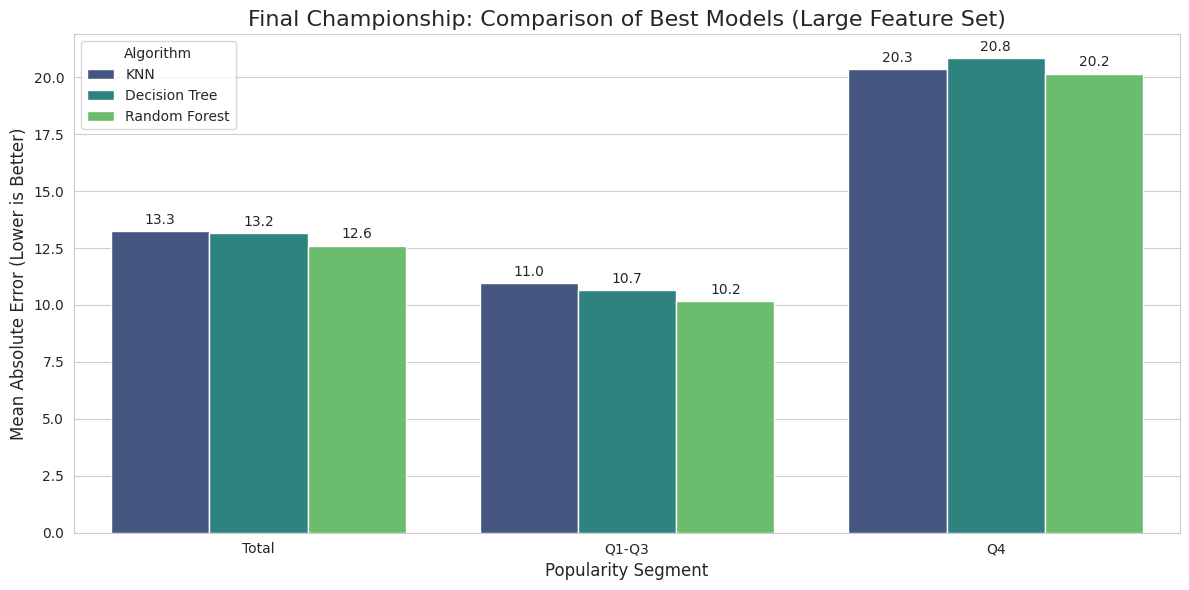

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Standardize the 'Group' column for KNN results
knn_results_large_standardized = quartiles_large.copy()
knn_results_large_standardized['Group'] = knn_results_large_standardized['Group'].replace({'TOTAL': 'Total', 'Q1–Q3': 'Q1-Q3'})

final_comparison = pd.concat([
    knn_results_large_standardized.assign(Model='KNN'), # Use corrected KNN results
    dt_results_large.assign(Model='Decision Tree'), # Use renamed Decision Tree results
    rf_results_large.assign(Model='Random Forest') # Use renamed Random Forest results
])


plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")


chart = sns.barplot(
    data=final_comparison,
    x='Group',       # הציר התחתון: Total, Q1-Q3, Q4
    y='MAE',         # הגובה: גודל השגיאה
    hue='Model',     # הצבעים: סוג האלגוריתם
    palette='viridis' # סכמת צבעים מקצועית
)


plt.title('Final Championship: Comparison of Best Models (Large Feature Set)', fontsize=16)
plt.ylabel('Mean Absolute Error (Lower is Better)', fontsize=12)
plt.xlabel('Popularity Segment', fontsize=12)
plt.legend(title='Algorithm')


for container in chart.containers:
    chart.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()